# Задача обнаружения аномалий в данных телеметрии оборудования

Сфер поиска аномалий в данных очень много - информационная безопасность, банковский сектор, государственное управление, медицина и многие другие предметные области. Нынешняя промышленная тенденция в отношении автоматизма и промышленных установок ведет нас к системам все более и более сложной мехатроники, работающим в неопределенной, эволюционирующей среде. Поэтому необходимо разрабатывать диагностические методы для обнаружения неисправностей, которые могут повлиять на работу этих систем, и локализации их причин (изоляция неисправностей). Данные методы необходимы для повышения производительности и ограничения последствий сбоев, которые могут быть катастрофическими для здоровья и жизни людей.

## Постановка задачи

Обнаружение аномалий в наборе данных с помощью обучения с учителем или без, и их пометка для дальнейшей работы с ними.

**Вход**: Массив данных телеметрии оборудования в текстовом файле *.csv*/*.txt*.

**Выход**: Массив соответствующих данным телеметрии бинарных значений о наличии аномалий.

## Пример набора данных

• [https://www.kaggle.com/datasets/arashnic/sensor-fault-detection-data?select=sensor-fault-detection.csv](https://www.kaggle.com/datasets/arashnic/sensor-fault-detection-data?select=sensor-fault-detection.csv)

## Предлагаемые архитектуры

• [https://www.sciencedirect.com/science/article/pii/S0306261920308114](https://www.sciencedirect.com/science/article/pii/S0306261920308114)

## Метод и источники

Без целевых меток используется **реконструкция временных окон**: дообучаем предобученную [MOMENT-1-small](https://huggingface.co/AutonLab/MOMENT-1-small) (Goswami et al., 2024), сравниваем с **LSTM Encoder–Decoder**.

Оценка - ошибка восстановления; пороги определяются на валидационном участке.

Истинные Precision/F1 без разметки вычислить нельзя.


## 1. Зависимости и параметры

Установку достаточно выполнить один раз. При конфликте версий перезапустите ядро.

In [ ]:
%pip install -q "numpy>=1.26,<3" "torch>=2.1" \
    "transformers>=4.54.1,<5" \
    "huggingface-hub>=0.24" \
    "kagglehub>=0.3" "pandas>=2.0" \
    "scikit-learn>=1.3" "matplotlib>=3.7"

%pip install -q --no-deps \
    "git+https://github.com/moment-timeseries-foundation-model/moment.git"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 90.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 87.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from copy import deepcopy
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import RobustScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
WINDOW = 512  # Длина контекста предобученной MOMENT.
TRAIN_STRIDE = 128
EVAL_STRIDE = 128
TRAIN_FRACTION = 0.60
VAL_FRACTION = 0.20
BATCH_SIZE = 8
MOMENT_EPOCHS = 3
LSTM_EPOCHS = 8
PATIENCE = 3
LEARNING_RATE_MOMENT = 2e-5
LEARNING_RATE_LSTM = 1e-3
MAX_TRAIN_WINDOWS = 1000  # Уберите ограничение для полного обучения.
MAX_VAL_WINDOWS = 300
THRESHOLD_QUANTILE = 0.99
DATA_PATH = None  # При необходимости: путь к локальному CSV/TXT.
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 2. Загрузка исходного датасета

Ищем `sensor-fault-detection.csv` в локальном каталоге или загружаем из Kaggle.

In [ ]:
def get_dataset_file(local_path=None):
    if local_path is not None:
        path = Path(local_path).expanduser()
        if not path.is_file():
            raise FileNotFoundError(path)
        return path

    for base in (Path.cwd(), Path("/kaggle/input")):
        if base.exists():
            matches = list(base.rglob("sensor-fault-detection.csv"))
            if matches:
                return matches[0]

    import kagglehub

    folder = Path(
        kagglehub.dataset_download("arashnic/sensor-fault-detection-data")
    )
    matches = list(folder.rglob("sensor-fault-detection.csv"))
    if not matches:
        raise FileNotFoundError("Не найден sensor-fault-detection.csv")
    return matches[0]


csv_path = get_dataset_file(DATA_PATH)
df = pd.read_csv(csv_path, sep=None, engine="python")
df.columns = df.columns.str.strip()
print("Файл:", csv_path)
print("Размер:", df.shape)
display(df.head())

Файл: /kaggle/input/sensor-fault-detection-data/sensor-fault-detection.csv
Размер: (62629, 3)


,Timestamp,SensorId,Value
0,2017-03-01T23:20:00+03:00,1,18.479807
1,2017-03-02T04:00:00+03:00,1,19.539112
2,2017-03-23T06:25:00+03:00,1,19.250198
3,2017-03-23T19:35:00+03:00,1,18.961285
4,2017-04-04T15:10:00+03:00,1,25.321623


## 3. Очистка, хронологическое разделение и масштабирование

Каждый датчик отдельный ряд; смешивать последовательности разных датчиков нельзя.

Масштабирование обучается **только** на train. Незаполненные исходные значения сохраняются для экспорта; для модели используются заполненные значения. Слишком короткие ряды не оцениваются.

In [ ]:
data = df[["Timestamp", "SensorId", "Value"]].copy()
data["original_index"] = np.arange(len(data))
data["Timestamp"] = pd.to_datetime(data["Timestamp"], errors="coerce")
data["Value"] = pd.to_numeric(data["Value"], errors="coerce")
data = data.dropna(subset=["Timestamp", "SensorId"])
data = data.sort_values(["SensorId", "Timestamp", "original_index"])
data = data.reset_index(drop=True)

segments = {"train": [], "val": [], "test": []}
min_length = WINDOW * 5
skipped = []

for sensor_id, group in data.groupby("SensorId", sort=False):
    group = group.copy().reset_index(drop=True)
    if len(group) < min_length:
        skipped.append((sensor_id, len(group)))
        continue

    n_train = int(len(group) * TRAIN_FRACTION)
    n_val = int(len(group) * VAL_FRACTION)
    bounds = [(0, n_train),
              (n_train, n_train + n_val),
              (n_train + n_val, len(group))]

    for split, (left, right) in zip(segments, bounds):
        part = group.iloc[left:right].copy().reset_index(drop=True)
        if len(part) < WINDOW:
            raise ValueError(f"Слишком короткий блок {split}: {sensor_id}")
        part["was_missing"] = part["Value"].isna()
        # Обработка независимо в пределах сегмента, без будущих тестовых данных.
        part["filled"] = part["Value"].ffill()
        train_median = group.iloc[:n_train]["Value"].median()
        if not np.isfinite(train_median):
            raise ValueError(f"У датчика {sensor_id} нет значений в train")
        part["filled"] = part["filled"].fillna(train_median)
        segments[split].append(part)

if not segments["train"]:
    raise ValueError("Нет рядов достаточной длины для разделения.")

scaler = RobustScaler()
scaler.fit(
    np.concatenate([part["filled"].to_numpy()
                    for part in segments["train"]]).reshape(-1, 1)
)

for parts in segments.values():
    for part in parts:
        part["scaled"] = scaler.transform(
            part[["filled"]].to_numpy()
        ).ravel().astype(np.float32)

print("Рядов для обучения:", len(segments["train"]))
print("Пропущено коротких рядов:", skipped[:10])
print("Длины:", {key: sum(len(part) for part in value)
                   for key, value in segments.items()})

Рядов для обучения: 1
Пропущено коротких рядов: []
Длины: {'train': 37577, 'val': 12525, 'test': 12527}


## 4. Формирование временных окон

Внутри каждого блока окна перекрываются; train и test никогда не пересекаются. Для ускорения обучения ограничивается **только** число обучающих/валидационных окон, не тестовых.

In [ ]:
def window_starts(length, window, stride):
    starts = list(range(0, length - window + 1, stride))
    last = length - window
    if not starts or starts[-1] != last:
        starts.append(last)
    return starts


def make_windows(parts, stride, max_windows=None):
    values = []
    locations = []
    for part_index, part in enumerate(parts):
        signal = part["scaled"].to_numpy(dtype=np.float32)
        for start in window_starts(len(signal), WINDOW, stride):
            values.append(signal[start:start + WINDOW])
            locations.append((part_index, start))
    if not values:
        raise ValueError("Не удалось сформировать окна")
    if max_windows is not None and len(values) > max_windows:
        # Равномерный выбор окон по всему обучающему периоду.
        selection = np.linspace(
            0, len(values) - 1, max_windows, dtype=int
        )
        values = [values[i] for i in selection]
        locations = [locations[i] for i in selection]
    return np.stack(values), locations


train_x, _ = make_windows(
    segments["train"], TRAIN_STRIDE, MAX_TRAIN_WINDOWS
)
val_x, _ = make_windows(
    segments["val"], EVAL_STRIDE, MAX_VAL_WINDOWS
)
test_x, test_locations = make_windows(segments["test"], EVAL_STRIDE)
print("Окна train / val / test:",
      len(train_x), len(val_x), len(test_x))


def loader_from_array(array, shuffle=False, batch_size=BATCH_SIZE):
    tensor = torch.from_numpy(array).unsqueeze(1)
    return DataLoader(
        TensorDataset(tensor), batch_size=batch_size, shuffle=shuffle
    )


train_loader = loader_from_array(train_x, shuffle=True)
val_loader = loader_from_array(val_x)
test_loader = loader_from_array(test_x)

Окна train / val / test: 291 95 95


## 5. Дообучение предобученной MOMENT

Загружаются **настоящие предобученные веса** `AutonLab/MOMENT-1-small`. Размораживаются последний блок Transformer и реконструкционная голова; остальные веса сохраняются. Оптимизируется masked-patch MSE, а не обучение классификатора на фиктивных метках. Для оценки аномалий реконструкция выполняется с фиксированной маской (через `reconstruct`) — это делает результат детерминированным, но оценивает лишь реконструкцию, а не истинную вероятность неисправности.

In [ ]:
from momentfm import MOMENTPipeline

moment_model = MOMENTPipeline.from_pretrained(
    "AutonLab/MOMENT-1-small",
    model_kwargs={
        "task_name": "reconstruction",
        "freeze_embedder": True,
        "freeze_encoder": True,
        "freeze_head": False,
        "mask_ratio": 0.3,
    },
)
moment_model.init()
moment_model.encoder.gradient_checkpointing = False

for parameter in moment_model.parameters():
    parameter.requires_grad = False
for parameter in moment_model.head.parameters():
    parameter.requires_grad = True
for parameter in moment_model.encoder.block[-1].parameters():
    parameter.requires_grad = True

moment_model = moment_model.to(DEVICE)
trainable = sum(
    parameter.numel() for parameter in moment_model.parameters()
    if parameter.requires_grad
)
print("Обучаемых параметров MOMENT:", trainable)

Обучаемых параметров MOMENT: 2364424


In [ ]:
def moment_step(model, batch, training):
    batch = batch.to(DEVICE)
    input_mask = torch.ones(batch.size(0), WINDOW, device=DEVICE)
    # Маска 1 означает видимый отсчёт; используем маскирование патчей.
    mask = model.mask_generator.generate_mask(x=batch, input_mask=input_mask).to(DEVICE)
    output = model( x_enc=batch, input_mask=input_mask, mask=mask).reconstruction
    hidden = (1.0 - mask).unsqueeze(1)
    error = (output - batch).square() * hidden
    return error.sum() / hidden.sum().clamp_min(1.0)


def fit_model(model, train_data, val_data, step_fn,
              epochs, learning_rate, checkpoint):
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=learning_rate,
    )
    best_loss = float("inf")
    best_state = None
    patience_left = PATIENCE
    history = []

    for epoch in range(1, epochs + 1):
        losses = {}
        for phase, batches in (("train", train_data), ("val", val_data)):
            model.train(phase == "train")
            running = 0.0
            count = 0
            for (batch,) in batches:
                with torch.set_grad_enabled(phase == "train"):
                    loss = step_fn(model, batch, phase == "train")
                    if phase == "train":
                        optimizer.zero_grad(set_to_none=True)
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(
                            model.parameters(), 1.0
                        )
                        optimizer.step()
                running += loss.item() * batch.size(0)
                count += len(batch)
            losses[phase] = running / max(1, count)
        history.append({"epoch": epoch, **losses})
        print(f"{checkpoint}: {epoch}/{epochs}, {losses}")
        if losses["val"] < best_loss:
            best_loss = losses["val"]
            best_state = deepcopy(model.state_dict())
            patience_left = PATIENCE
        else:
            patience_left -= 1
            if patience_left == 0:
                break

    model.load_state_dict(best_state)
    torch.save(best_state, OUTPUT_DIR / checkpoint)
    return pd.DataFrame(history)


moment_history = fit_model(
    moment_model, train_loader, val_loader, moment_step,
    MOMENT_EPOCHS, LEARNING_RATE_MOMENT, "moment_finetuned.pt"
)

moment_finetuned.pt: 1/3, {'train': 0.3202768541693278, 'val': 0.07593967412647448}
moment_finetuned.pt: 2/3, {'train': 0.24384222043953402, 'val': 0.07426463812589645}
moment_finetuned.pt: 3/3, {'train': 0.25716603908342184, 'val': 0.06909587179359637}


## 6. Baseline: LSTM Encoder–Decoder (EncDec-AD)

Двухслойный LSTM-энкодер кодирует окно в скрытое состояние; LSTM-декодер восстанавливает его **в обратном порядке**, как в идее EncDec-AD. Это самостоятельное обучение с нуля, без использования меток.

In [ ]:
class LSTMEncoderDecoder(nn.Module):
    def __init__(self, hidden_size=64, num_layers=2):
        super().__init__()
        self.encoder = nn.LSTM(
            1, hidden_size, num_layers=num_layers, batch_first=True
        )
        self.decoder = nn.LSTM(
            1, hidden_size, num_layers=num_layers, batch_first=True
        )
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence = x.transpose(1, 2)
        _, state = self.encoder(sequence)
        decoder_input = torch.zeros_like(sequence)
        decoded, _ = self.decoder(decoder_input, state)
        reconstruction = self.output_layer(decoded).flip(dims=[1])
        return reconstruction.transpose(1, 2)


def lstm_step(model, batch, training):
    batch = batch.to(DEVICE)
    return (model(batch) - batch).square().mean()


lstm_model = LSTMEncoderDecoder().to(DEVICE)
lstm_history = fit_model(
    lstm_model, train_loader, val_loader, lstm_step,
    LSTM_EPOCHS, LEARNING_RATE_LSTM, "lstm_encdec.pt"
)

lstm_encdec.pt: 1/8, {'train': 0.8423678973286423, 'val': 1.5711865795286077}
lstm_encdec.pt: 2/8, {'train': 0.8299058069478196, 'val': 1.4165088863749253}
lstm_encdec.pt: 3/8, {'train': 0.4866632857580775, 'val': 0.8520360636083704}
lstm_encdec.pt: 4/8, {'train': 0.4086497854121362, 'val': 0.6293459730712991}
lstm_encdec.pt: 5/8, {'train': 0.6942110873784396, 'val': 0.3494215333148053}
lstm_encdec.pt: 6/8, {'train': 0.5479691024498432, 'val': 0.48059879149261275}
lstm_encdec.pt: 7/8, {'train': 0.4718254692980514, 'val': 0.4635933540369335}
lstm_encdec.pt: 8/8, {'train': 0.38917966381585883, 'val': 0.7343060404062272}


## 7. Оценки аномальности и калибровка порога

Для обеих моделей считаем ошибку на каждом отсчёте окна и усредняем её в местах перекрытия. Порог (99-й процентиль) определяется **только по валидации**; тест не используется для подбора порога. Это эвристика, а не гарантированный уровень ложных тревог.

In [ ]:
@torch.no_grad()
def point_errors(model, windows, kind):
    model.eval()
    output = []
    batches = loader_from_array(windows, batch_size=BATCH_SIZE)
    for (batch,) in batches:
        batch = batch.to(DEVICE)
        if kind == "moment":
            reconstruction = model.reconstruct(
                x_enc=batch,
                input_mask=torch.ones(
                    batch.size(0), WINDOW, device=DEVICE
                ),
            ).reconstruction
        else:
            reconstruction = model(batch)
        error = (reconstruction - batch).square().squeeze(1)
        output.append(error.cpu().numpy())
    return np.concatenate(output)


def aggregate_scores(parts, locations, errors):
    totals = [np.zeros(len(part), dtype=np.float64) for part in parts]
    counts = [np.zeros(len(part), dtype=np.int64) for part in parts]
    for (part_index, start), error in zip(locations, errors):
        end = start + WINDOW
        totals[part_index][start:end] += error
        counts[part_index][start:end] += 1
    return [
        np.divide(total, count, out=np.full_like(total, np.nan),
                  where=count > 0)
        for total, count in zip(totals, counts)
    ]


def calibration_scores(model, kind):
    # Для порога используем все валидационные окна (без усечения).
    windows, locations = make_windows(segments["val"], EVAL_STRIDE)
    errors = point_errors(model, windows, kind)
    per_sensor = aggregate_scores(segments["val"], locations, errors)
    return np.concatenate(per_sensor)


moment_cal = calibration_scores(moment_model, "moment")
lstm_cal = calibration_scores(lstm_model, "lstm")
thresholds = {
    "moment": float(np.nanquantile(moment_cal, THRESHOLD_QUANTILE)),
    "lstm": float(np.nanquantile(lstm_cal, THRESHOLD_QUANTILE)),
}
print("Пороги:", thresholds)

Пороги: {'moment': 0.493544476851821, 'lstm': 2.185628448724748}


## 8. Сравнение и бинарные предсказания

Результат: `0` — ниже порога, `1` — выше. Оценки относятся к **тестовой части** ряда. Дополнительно экспортируется флаг исходного пропуска; он помечается как аномалия по правилу контроля качества, независимо от модели. Точки остальных периодов сохраняются в файле с признаком `evaluated=False`, а бинарный класс для них не вычисляется.

In [ ]:
moment_errors = point_errors(moment_model, test_x, "moment")
lstm_errors = point_errors(lstm_model, test_x, "lstm")
moment_scores = aggregate_scores(
    segments["test"], test_locations, moment_errors
)
lstm_scores = aggregate_scores(
    segments["test"], test_locations, lstm_errors
)

frames = []
for part, moment_score, lstm_score in zip(
    segments["test"], moment_scores, lstm_scores
):
    result = part[[
        "original_index", "Timestamp", "SensorId", "Value", "was_missing"
    ]].copy()
    result["moment_score"] = moment_score
    result["lstm_score"] = lstm_score
    result["evaluated"] = np.isfinite(moment_score) & np.isfinite(lstm_score)
    result["moment_anomaly"] = (
        (moment_score > thresholds["moment"]) | result["was_missing"]
    ).astype("int8")
    result["lstm_anomaly"] = (
        (lstm_score > thresholds["lstm"]) | result["was_missing"]
    ).astype("int8")
    frames.append(result)

results = pd.concat(frames, ignore_index=True)
if not results["evaluated"].all():
    raise RuntimeError("Есть тестовые точки, не покрытые окнами")

results.sort_values("original_index").to_csv(
    OUTPUT_DIR / "anomaly_predictions.csv", index=False
)
comparison = pd.DataFrame({
    "model": ["MOMENT fine-tuned", "LSTM EncDec-AD"],
    "val_threshold": [thresholds["moment"], thresholds["lstm"]],
    "test_anomalies": [
        int(results["moment_anomaly"].sum()),
        int(results["lstm_anomaly"].sum()),
    ],
    "test_anomaly_rate": [
        results["moment_anomaly"].mean(),
        results["lstm_anomaly"].mean(),
    ],
    "test_mean_score": [
        results["moment_score"].mean(),
        results["lstm_score"].mean(),
    ],
})
comparison.to_csv(OUTPUT_DIR / "comparison.csv", index=False)
display(comparison)
display(results.head())

,model,val_threshold,test_anomalies,test_anomaly_rate,test_mean_score
0,MOMENT fine-tuned,0.493544,134,0.010697,0.060631
1,LSTM EncDec-AD,2.185628,0,0.000000,0.200035


,original_index,Timestamp,SensorId,Value,was_missing,moment_score,lstm_score,evaluated,moment_anomaly,lstm_anomaly
0,15684,2017-07-18 21:10:00+03:00,1,31.787771,False,0.275482,0.365982,True,0,0
1,25129,2017-07-18 21:15:00+03:00,1,31.691204,False,0.255350,0.346691,True,0,0
2,54546,2017-07-18 21:20:00+03:00,1,31.594618,False,0.226774,0.327918,True,0,0
3,39259,2017-07-18 21:25:00+03:00,1,31.594618,False,0.079140,0.327918,True,0,0
4,17098,2017-07-18 21:30:00+03:00,1,31.498051,False,0.205449,0.309672,True,0,0


## 9. Графики и итог

Ошибки двух моделей имеют разные масштабы, поэтому показания аномалий отображаются отдельно. Число найденных аномалий **не является** метрикой качества без независимой разметки.

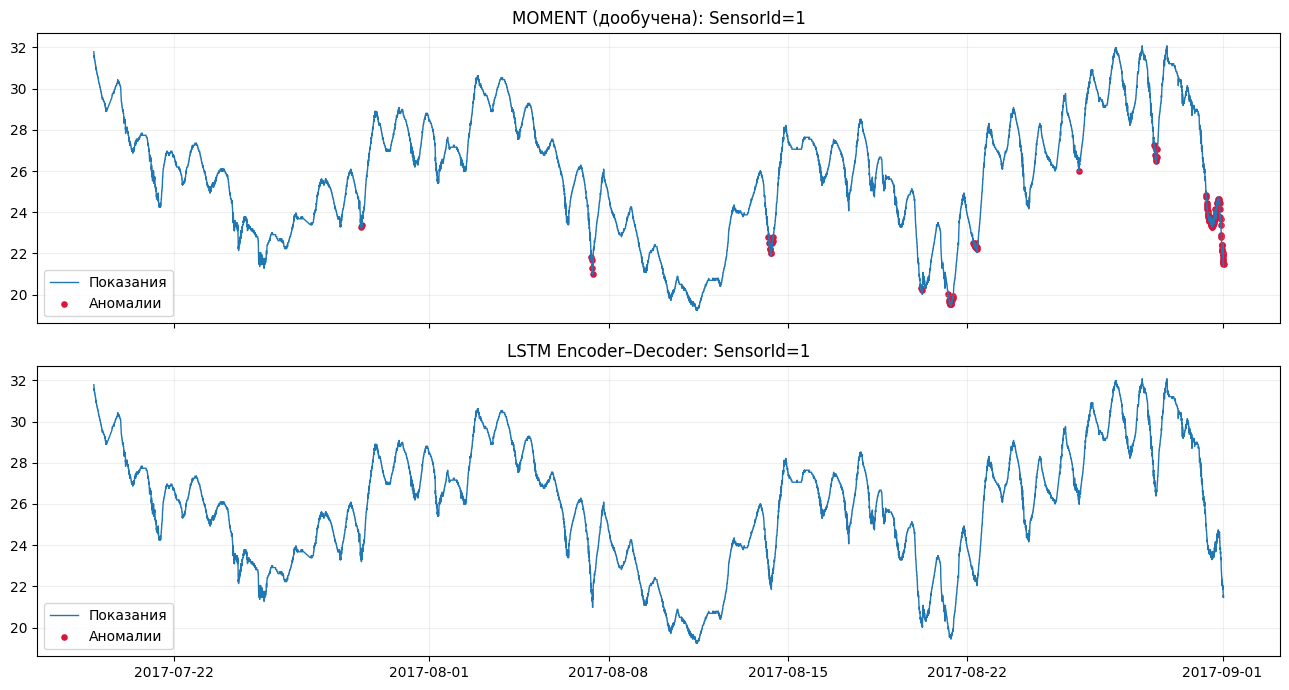

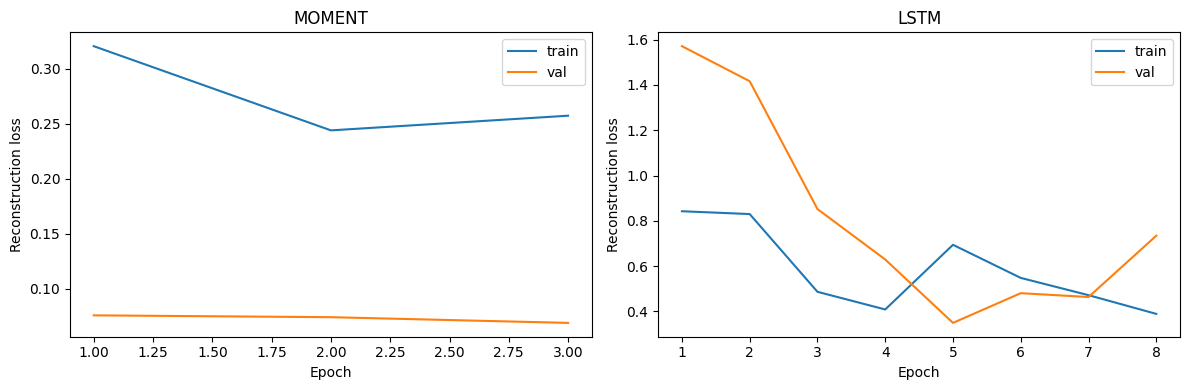

In [ ]:
figure, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
sensor = results["SensorId"].iloc[0]
view = results[results["SensorId"] == sensor].copy()
for axis, model_name, column in zip(
    axes,
    ("MOMENT (дообучена)", "LSTM Encoder–Decoder"),
    ("moment_anomaly", "lstm_anomaly"),
):
    axis.plot(view["Timestamp"], view["Value"], lw=1, label="Показания")
    anomalous = view[view[column] == 1]
    axis.scatter(anomalous["Timestamp"], anomalous["Value"],
                 color="crimson", s=14, label="Аномалии")
    axis.set_title(f"{model_name}: SensorId={sensor}")
    axis.legend()
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, history, label in zip(
    axes, (moment_history, lstm_history), ("MOMENT", "LSTM")
):
    axis.plot(history["epoch"], history["train"], label="train")
    axis.plot(history["epoch"], history["val"], label="val")
    axis.set_title(label)
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Reconstruction loss")
    axis.legend()
plt.tight_layout()
plt.show()